# Analizar e interpretar

## Hallazgos y decisiones del primer notebook

Este trabajo hace un análisis descriptivo de los delitos registrados por el departamento de policía de Los Angeles (LAPD) entre 2020 y 2023, en las 21 áreas geográficas en que dicho departamento divide la ciudad. Cada fila representa un incidente delictivo. Es importante precisar que cada incidente registra el delito principal y puede contener también otros delitos, por lo que un incidente no equivale necesariamente a un solo delito. Este análisis utiliza únicamente el delito principal de cada incidente.


Como parte de la limpieza se seleccionaron las variables:
- **fecha_occ:** fecha y hora de ocurrencia (creada a partir de los campos 'DATE OCC' y 'TIME OCC')
- **hora_occ:** hora de ocurrencia (creada a partir del campo 'TIME OCC')
- **diasem:** día de la semana (creada a partir del campo 'DATE OCC')
- **anio:** año de ocurrencia (creada a partir del campo 'DATE OCC')
- **num_area:** número de área geográfica
- **nom_area:** nombre del área geográfica
- **delito:** la descripción del delito principal registrado en el incidente
- **sexo_vic:** el sexo registrado de la víctima
- **edad_vic:** la edad registrada de la víctima


Entre los *principales hallazgos* de la limpieza (ver `nb01_estructura_perfilado.ipynb`) encontramos:
- **1:** la variable `sexo_vic` presentaba valores no previstos en la documentación del archivo (`H` y `-`), que en la capa `clean` se recodificaron como valores nulos. Solo se conservan los valores documentados: F (mujer), M (hombre) y X (desconocido).
- **2:** la variable `edad_vic` presentaba valores no válidos como edad de una persona: valores negativos (de −4 a −1), una frecuencia muy alta del valor cero (269,178 registros) y un valor aislado de 120. Como la documentación no explica su significado, se recodificaron como valores nulos. El valor 99 se conservó: su frecuencia (354) es mucho mayor que la de 98 (71), pero no hay registros entre 100 y 119, lo que sugiere que funciona como valor tope («99 años o más») y no como código de edad desconocida.
- **3:** aunque el archivo contiene datos de 2020 a 2024, decidimos excluir el último año, porque la documentación explica que, a partir de marzo de 2024, el LAPD comenzó a migrar hacia un nuevo sistema de registro de incidentes delictivos (UCR → NIBRS). En 2024 se siguieron registrando incidentes, pero con una reducción significativa y sin aclaración sobre qué tipo de incidentes dejaron de considerarse. Para evitar sesgos, dejamos ese año fuera del análisis; el recorte se aplica en la capa `model`.


Las cinco preguntas que guían el análisis son:
1. **Pregunta 1:** ¿Cuáles son los tres delitos más frecuentes en el acumulado 2020–2023, según el sexo de la víctima?
2. **Pregunta 2:** ¿Cómo evolucionaron por año (2020–2023) los tres delitos más frecuentes de cada sexo?
3. **Pregunta 3:** ¿En qué días de la semana y horas ocurre el principal delito de cada sexo?
4. **Pregunta 4:** ¿Las áreas que concentran el 50 % de los delitos con víctima mujer son las mismas que para víctima hombre?
5. **Pregunta 5:** ¿Qué áreas concentran el 50 % del principal delito de cada sexo, y cómo se comparan con el total de delitos (pregunta 4)?

Las cinco preguntas usan el mismo universo: 683,121 registros de 2020–2023 con víctima registrada como mujer (F) u hombre (M), equivalentes al 77.9 % de los registros del periodo. Quedan fuera los registros con sexo desconocido (X) o faltante.


**Glosario de delitos.** Las figuras conservan los nombres originales del LAPD; en el texto se usan las siguientes equivalencias:

| Nombre en la base (LAPD) | Equivalencia en el texto |
|---|---|
| INTIMATE PARTNER - SIMPLE ASSAULT | lesión simple por parte de la pareja íntima |
| BATTERY - SIMPLE ASSAULT | lesión física simple |
| THEFT OF IDENTITY | robo de identidad |
| ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT | lesión agravada con arma mortal |
| BURGLARY FROM VEHICLE | robo al interior de vehículos |


In [1]:
#Importar paqueterías:
import pandas as pd              
import duckdb                     
import matplotlib.pyplot as plt  
import seaborn as sns 

#Conexión con el archivo de la base:
con = duckdb.connect("../data/db/delitos_LA.duckdb", read_only=True)  

### Pregunta 1: ¿Cuáles son los tres delitos más frecuentes en el acumulado 2020–2023, según el sexo de la víctima?


- *Unidad de análisis:*\
combinación sexo de la víctima × tipo de delito (tabla `model.del_sexo`, sumando los años)

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) entre 2020 y 2023

In [2]:
#Ejecuta una consulta SQL
del_sexo = con.execute("""
    SELECT sexo_vic,
           delito,
           SUM(n_delitos)::BIGINT AS n_delitos
    FROM model.del_sexo
    GROUP BY sexo_vic, delito
""").df()

del_sexo_anio = con.execute("SELECT * FROM model.del_sexo").df()

del_dia_hora = con.execute("SELECT * FROM model.del_dia_hora").df()

assert del_dia_hora["n_delitos"].sum() == del_sexo["n_delitos"].sum()

del_area = con.execute("SELECT * FROM model.del_area").df()

In [3]:
# Función: devuelve los n delitos más frecuentes, según el sexo de la víctima registrada
def top_delitos(df, sexo, n=3):
    return (df[df["sexo_vic"] == sexo]
            .sort_values("n_delitos", ascending=False)
            .head(n))

# Top 3 para mujeres (F) y para hombres (M)
df_muj = top_delitos(del_sexo, "F")
df_hom = top_delitos(del_sexo, "M")

print("Los 3 delitos más frecuentes en mujeres, 2020-2023:")
print(df_muj)
print("\nLos 3 delitos más frecuentes en hombres, 2020-2023:")
print(df_hom)

Los 3 delitos más frecuentes en mujeres, 2020-2023:
    sexo_vic                             delito  n_delitos
29         F  INTIMATE PARTNER - SIMPLE ASSAULT      33193
119        F           BATTERY - SIMPLE ASSAULT      32641
105        F                  THEFT OF IDENTITY      32435

Los 3 delitos más frecuentes en hombres, 2020-2023:
    sexo_vic                                          delito  n_delitos
67         M                        BATTERY - SIMPLE ASSAULT      36359
103        M  ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT      35579
33         M                           BURGLARY FROM VEHICLE      30244


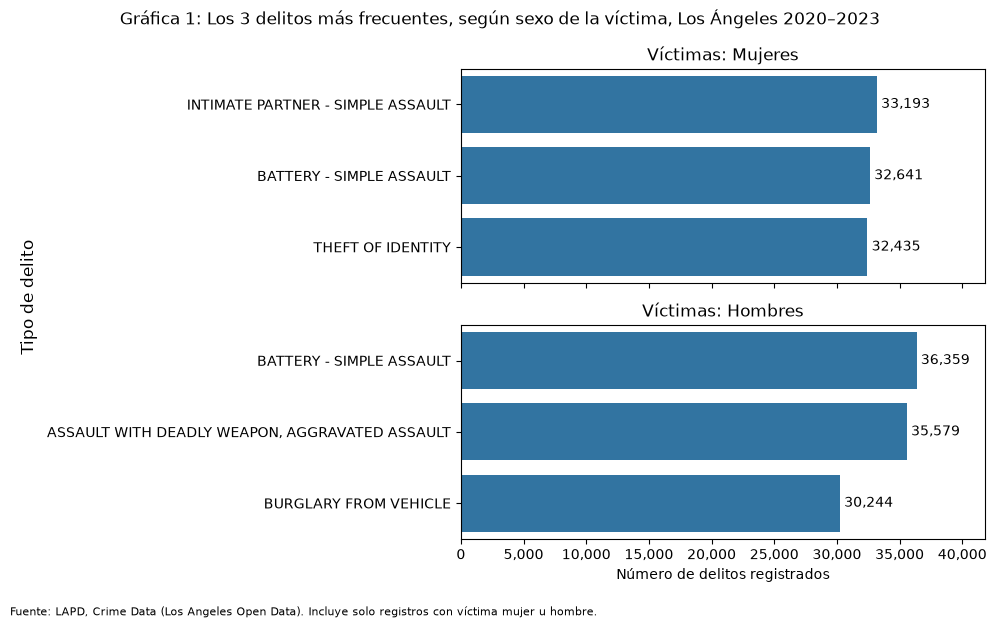

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Panel superior: mujeres
sns.barplot(data=df_muj, x="n_delitos", y="delito", ax=axes[0])
axes[0].set_title("Víctimas: Mujeres")
axes[0].set_ylabel("")
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", padding=3)

# Panel inferior: hombres
sns.barplot(data=df_hom, x="n_delitos", y="delito", ax=axes[1])
axes[1].set_title("Víctimas: Hombres")
axes[1].set_ylabel("")
axes[1].set_xlabel("Número de delitos registrados")
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)

# Eje X: separador de miles y espacio extra para las cifras
limite = max(df_muj["n_delitos"].max(), df_hom["n_delitos"].max()) * 1.15
axes[1].set_xlim(0, limite)
axes[1].xaxis.set_major_formatter("{x:,.0f}")

fig.suptitle("Gráfica 1: Los 3 delitos más frecuentes, según sexo de la víctima, Los Ángeles 2020–2023")
fig.supylabel("Tipo de delito")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_01.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 1

En las mujeres, los tres delitos más frecuentes durante 2020–2023 fueron la lesión simple por parte de la pareja íntima (33,193 registros), la lesión física simple (32,641) y el robo de identidad (32,435). Las diferencias entre los tres son menores al 2.5 %, por lo que su orden debe leerse como un empate práctico: lo relevante no es cuál ocupa el primer lugar, sino que un delito de pareja íntima forma parte de los tres principales.

En los hombres, los tres delitos más frecuentes fueron la lesión física simple (36,359), la lesión agravada con arma mortal (35,579) y el robo al interior de vehículos (30,244).

Así, la lesión física simple es común a ambos sexos, pero el resto de la composición difiere: entre las mujeres aparece un delito asociado a la violencia de pareja, que no figura entre los tres principales de los hombres; entre los hombres aparecen una lesión agravada y un delito patrimonial. Esto es consistente con la violencia de género como un fenómeno que afecta de manera diferenciada a las mujeres, aunque estos datos, por sí solos, no permiten establecer sus causas.

**Limitaciones:**
- El análisis incluye solo registros con víctima mujer u hombre (77.9 % del periodo). Quedan fuera los registros con sexo desconocido (X) o faltante; presumiblemente por ello no aparecen delitos que con frecuencia no tienen una víctima persona identificada, como el robo de vehículo, que es el delito más frecuente de toda la base.
- Los registros representan incidentes conocidos por el LAPD, no la totalidad de los delitos ocurridos; la violencia de pareja, en particular, tiende a denunciarse menos que otros delitos. Para dimensionar la probabilidad de victimización según sexo y tipo de delito, el análisis debería complementarse con encuestas de victimización locales y encuestas de violencia de género.

### Pregunta 2: ¿Cómo evolucionaron por año (2020–2023) los tres delitos más frecuentes de cada sexo?

- *Unidad de análisis:*\
combinación sexo de la víctima × tipo de delito × año de ocurrencia (tabla `model.del_sexo`)

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) ocurridos entre 2020 y 2023

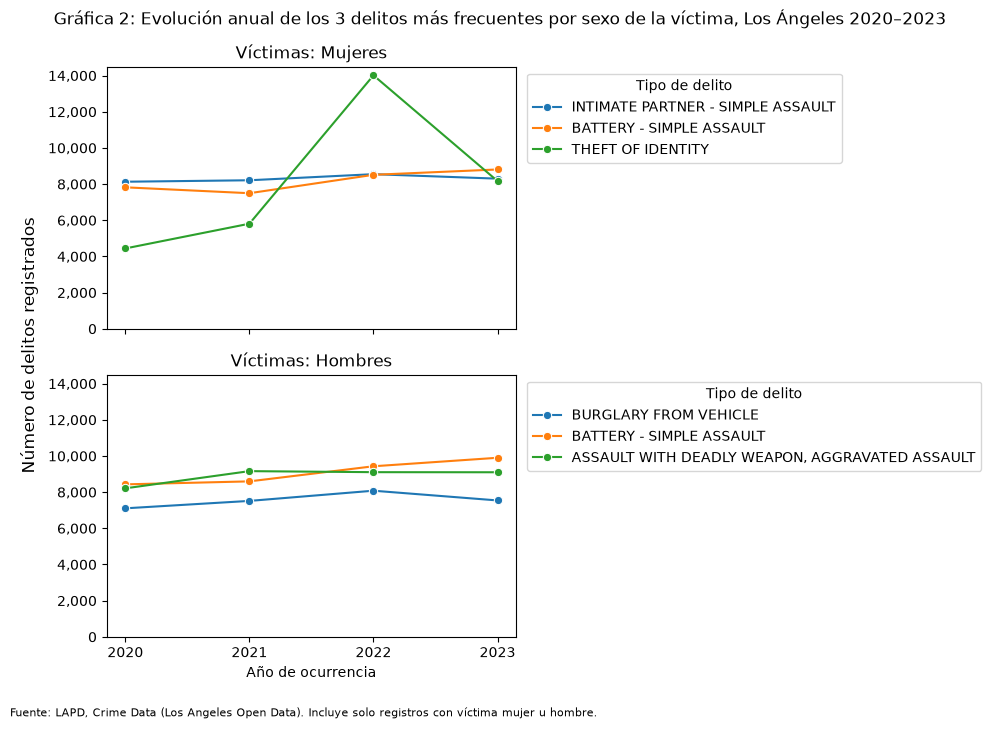

In [5]:
# Datos: solo los 3 principales delitos de cada sexo (identificados en la pregunta 1)
anio_muj = del_sexo_anio[(del_sexo_anio["sexo_vic"] == "F") &
                         (del_sexo_anio["delito"].isin(df_muj["delito"]))]
anio_hom = del_sexo_anio[(del_sexo_anio["sexo_vic"] == "M") &
                         (del_sexo_anio["delito"].isin(df_hom["delito"]))]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, sharey=True)

# Panel mujeres
sns.lineplot(data=anio_muj, x="anio", y="n_delitos", hue="delito",
             marker="o", errorbar=None, ax=axes[0])
axes[0].set_title("Víctimas: Mujeres")
axes[0].set_ylabel("")
sns.move_legend(axes[0], "upper left", bbox_to_anchor=(1.01, 1), title="Tipo de delito")

# Panel hombres
sns.lineplot(data=anio_hom, x="anio", y="n_delitos", hue="delito",
             marker="o", errorbar=None, ax=axes[1])
axes[1].set_title("Víctimas: Hombres")
axes[1].set_xlabel("Año de ocurrencia")
axes[1].set_ylabel("")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.01, 1), title="Tipo de delito")

# Ejes: un tick por año, separador de miles y eje Y desde cero
axes[1].set_xticks(sorted(del_sexo_anio["anio"].unique()))
axes[1].yaxis.set_major_formatter("{x:,.0f}")
axes[1].set_ylim(bottom=0)

fig.suptitle("Gráfica 2: Evolución anual de los 3 delitos más frecuentes por sexo de la víctima, Los Ángeles 2020–2023")
fig.supylabel("Número de delitos registrados")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_02.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 2

Esta gráfica ofrece tres hallazgos importantes:
- Primero, en los delitos con víctima mujer, la lesión física simple y la lesión simple por parte de la pareja íntima se mantienen relativamente estables en el periodo. En cambio, el robo de identidad tiene un comportamiento atípico: pasa de alrededor de 4,500 registros en 2020 a cerca de 14,000 en 2022, y en 2023 regresa a niveles cercanos a los de los otros dos delitos. Cerca del 43 % de sus registros acumulados corresponde a 2022, por lo que su lugar entre los tres principales delitos de la pregunta 1 depende en buena medida de ese año.
- Segundo, en los delitos con víctima hombre, los tres principales se mantuvieron relativamente estables; se aprecia un ligero aumento sostenido de la lesión física simple y una caída del robo al interior de vehículos en 2023.
- Tercero, a pesar de la pandemia de COVID-19, los delitos violentos de ambos sexos no muestran cambios marcados en 2020 respecto a 2021.

**Limitaciones:**
- Cada serie tiene solo cuatro observaciones anuales, por lo que la gráfica describe cambios entre años, no tendencias.
- Los cambios en los registros pueden reflejar cambios en la ocurrencia, en la denuncia o en las prácticas de registro.

### Pregunta 3: ¿En qué días de la semana y horas ocurre el principal delito de cada sexo?

- *Unidad de análisis:*\
combinación día de la semana × hora de ocurrencia, para el principal delito de cada sexo (tabla `model.del_dia_hora`)

- *Universo:*\
registros 2020–2023 del principal delito de cada sexo: lesión simple por parte de la pareja íntima con víctima mujer (33,193) y lesión física simple con víctima hombre (36,359)

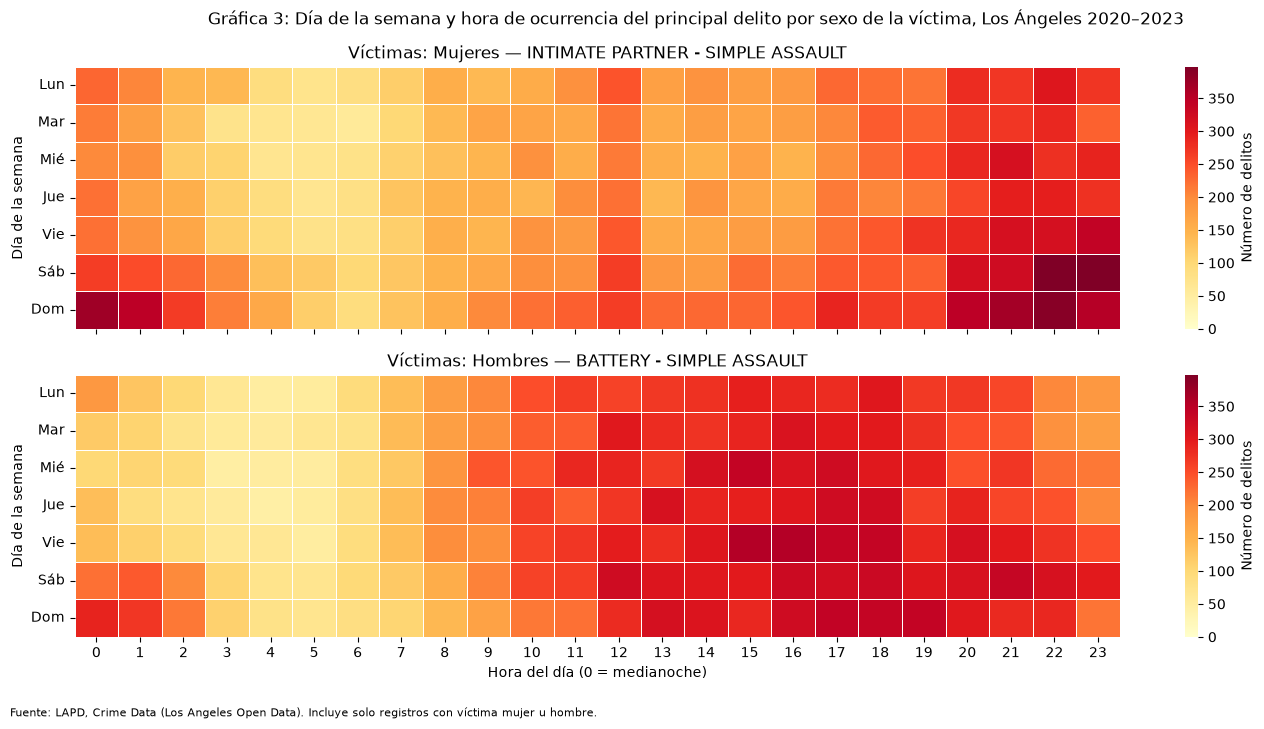

In [6]:
# Principal delito de cada sexo: primera fila del top 3 de la pregunta 1
delito_muj = df_muj["delito"].iloc[0]
delito_hom = df_hom["delito"].iloc[0]

# Datos de cada sexo, solo para su principal delito
dh_muj = del_dia_hora[(del_dia_hora["sexo_vic"] == "F") &
                      (del_dia_hora["delito"] == delito_muj)]
dh_hom = del_dia_hora[(del_dia_hora["sexo_vic"] == "M") &
                      (del_dia_hora["delito"] == delito_hom)]

# Tabla cruzada: días en filas, horas en columnas, conteos en las celdas
tabla_muj = dh_muj.pivot_table(index="diasem", columns="hora_occ",
                               values="n_delitos", aggfunc="sum", fill_value=0)
tabla_hom = dh_hom.pivot_table(index="diasem", columns="hora_occ",
                               values="n_delitos", aggfunc="sum", fill_value=0)

# Nombres de los días (diasem: 1 = lunes ... 7 = domingo)
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
tabla_muj.index = dias
tabla_hom.index = dias

# Misma escala de color en ambos paneles
vmax = max(tabla_muj.max().max(), tabla_hom.max().max())

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Panel superior: mujeres
sns.heatmap(tabla_muj, cmap="YlOrRd", vmin=0, vmax=vmax, linewidths=0.5,
            cbar_kws={"label": "Número de delitos"}, ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres — {delito_muj}")
axes[0].set_xlabel("")
axes[0].set_ylabel("Día de la semana")
axes[0].tick_params(axis="y", rotation=0)

# Panel inferior: hombres
sns.heatmap(tabla_hom, cmap="YlOrRd", vmin=0, vmax=vmax, linewidths=0.5,
            cbar_kws={"label": "Número de delitos"}, ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres — {delito_hom}")
axes[1].set_xlabel("Hora del día (0 = medianoche)")
axes[1].set_ylabel("Día de la semana")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 3: Día de la semana y hora de ocurrencia del principal delito por sexo de la víctima, Los Ángeles 2020–2023")
fig.text(0.01, -0.03, "Fuente: LAPD, Crime Data (Los Angeles Open Data). "
                     "Incluye solo registros con víctima mujer u hombre.", fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_03.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 3

- En los delitos con víctima mujer, la gráfica muestra un patrón claro: la lesión simple por parte de la pareja íntima es más frecuente en las noches, de las 20 a las 23 horas, y alcanza su máximo en los fines de semana, entre las 22 horas del sábado y la 01 hora del domingo.
- En los delitos con víctima hombre, el patrón es más disperso: la lesión física simple se concentra en la tarde, entre las 12 y las 19 horas, con mayor frecuencia de miércoles a domingo y un máximo el viernes por la tarde; en fin de semana se extiende hacia la noche y la madrugada.
- El contraste sugiere dinámicas distintas: la violencia de pareja coincide con horarios de convivencia en el hogar, mientras que la lesión simple contra hombres coincide con horarios de actividad fuera de casa. Una forma de interpretarlo es la teoría de las actividades rutinarias (Cohen y Felson, 1979, *American Sociological Review*, 44(4), 588–608), según la cual el delito ocurre cuando coinciden en tiempo y espacio un agresor motivado, una víctima disponible y la ausencia de un guardián capaz. Se trata de una hipótesis: los datos muestran cuándo ocurren los delitos, no por qué.

**Limitaciones:**
- Los registros reflejan incidentes conocidos por el LAPD; el patrón horario puede verse afectado por diferencias en la denuncia según el momento del día.

### Pregunta 4: ¿Las áreas que concentran el 50 % de los delitos con víctima mujer son las mismas que para víctima hombre?

- *Unidad de análisis:*\
combinación área geográfica × sexo de la víctima, sumando todos los delitos (tabla `model.del_area`)

- *Universo:*\
683,121 registros con víctima mujer (F) u hombre (M) entre 2020 y 2023

In [7]:
# Primero calculamos el porcentaje acumulado para distinguir qué áreas 
# concentran más de 50% de los delitos reportados

# Sumar todos los delitos por área y sexo
area_sexo = (del_area
             .groupby(["sexo_vic", "nom_area"], as_index=False)["n_delitos"]
             .sum())

# Después creamos una función que ordena las áreas de un sexo y marca las que concentran el 50 %
def areas_50(df, sexo):
    datos = (df[df["sexo_vic"] == sexo]
             .sort_values("n_delitos", ascending=False)
             .reset_index(drop=True))
    datos["pct"] = 100 * datos["n_delitos"] / datos["n_delitos"].sum()
    datos["pct_acum"] = datos["pct"].cumsum()
    # Un área entra al grupo si el acumulado ANTES de ella era menor a 50
    datos["grupo_50"] = (datos["pct_acum"] - datos["pct"]) < 50
    datos["grupo"] = datos["grupo_50"].map({True: "Concentran el 50 %", False: "Resto"})
    return datos

areas_muj = areas_50(area_sexo, "F")
areas_hom = areas_50(area_sexo, "M")

# Imprime las primeras filas de cada sexo
print(areas_muj[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))
print(areas_hom[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))


      nom_area       pct   pct_acum  grupo_50
0  77th Street  7.554730   7.554730      True
1    Southwest  6.283513  13.838243      True
2    Southeast  6.212494  20.050737      True
3      Central  5.907327  25.958064      True
4      Pacific  5.192791  31.150856      True
5      Olympic  4.919878  36.070734      True
6       Newton  4.907473  40.978207      True
7    Hollywood  4.880802  45.859009      True
8  N Hollywood  4.678288  50.537298      True
9     Wilshire  4.549275  55.086572     False
      nom_area       pct   pct_acum  grupo_50
0      Central  8.268131   8.268131      True
1  N Hollywood  6.230834  14.498966      True
2      Pacific  5.759217  20.258183      True
3    Hollywood  5.471423  25.729606      True
4      Topanga  5.270133  30.999739      True
5  West Valley  5.241853  36.241592      True
6       Newton  5.022541  41.264133      True
7  77th Street  4.974853  46.238986      True
8     Wilshire  4.883080  51.122066      True
9      West LA  4.776890  55.89895

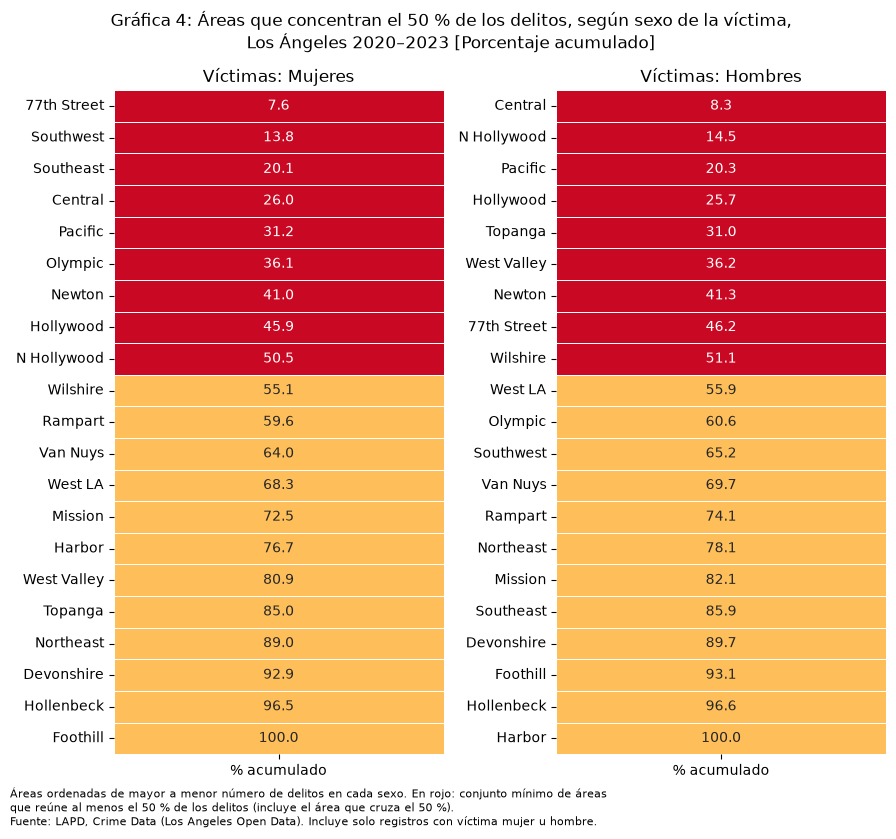

In [8]:
# Dos colores de la paleta del mapa de calor: 0 = resto, 1 = concentran el 50 %
colores = sns.color_palette("YlOrRd", 5)
colores_grupo = [colores[1], colores[4]]

# Número de áreas en el grupo del 50 % (para los títulos)
n_muj = areas_muj["grupo_50"].sum()
n_hom = areas_hom["grupo_50"].sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 8))

# Panel izquierdo: mujeres
sns.heatmap(areas_muj.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_muj[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres")
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)

# Panel derecho: hombres
sns.heatmap(areas_hom.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_hom[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres")
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 4: Áreas que concentran el 50 % de los delitos, según sexo de la víctima,\nLos Ángeles 2020–2023 [Porcentaje acumulado]")
fig.text(0.01, -0.04,
         "Áreas ordenadas de mayor a menor número de delitos en cada sexo. En rojo: conjunto mínimo de áreas\n"
         "que reúne al menos el 50 % de los delitos (incluye el área que cruza el 50 %).\n"
         "Fuente: LAPD, Crime Data (Los Angeles Open Data). Incluye solo registros con víctima mujer u hombre.",
         fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_04.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 4

- 9 de las 21 áreas geográficas reúnen al menos el 50 % de los delitos registrados, tanto para víctimas mujeres como para víctimas hombres.
- Las áreas coinciden solo en parte: 6 de las 9 están en ambos grupos (Central, 77th Street, Pacific, Newton, Hollywood y N Hollywood).
- Southwest, Southeast y Olympic forman parte del grupo solo para víctimas mujeres; Topanga, West Valley y Wilshire, solo para víctimas hombres.

**Limitaciones:**
- La concentración se mide con cifras absolutas, no con tasas, por lo que no representa riesgo relativo: un área puede concentrar más delitos porque tiene más población o porque recibe más personas por trabajo, turismo u otros motivos.
- Solo se incluyen delitos con víctima mujer u hombre; delitos como el robo de vehículo no aparecen y podrían modificar el patrón.
- El ejercicio utiliza las 21 áreas administrativas del LAPD, que son unidades grandes. Una concentración moderada a esta escala no descarta concentraciones mayores en escalas más finas (calles o cuadras), que podrían analizarse mediante mapas de calor.

### Pregunta 5: ¿Qué áreas concentran el 50 % del principal delito de cada sexo, y cómo se comparan con el total de delitos?

- *Unidad de análisis:*\
área geográfica, para el principal delito de cada sexo (tabla `model.del_area`)

- *Universo:*\
registros 2020–2023 de la lesión simple por parte de la pareja íntima con víctima mujer (33,193) y de la lesión física simple con víctima hombre (36,359)

In [9]:
# Principal delito de cada sexo (delito_muj y delito_hom vienen de la pregunta 3)
area_del_muj = del_area[(del_area["sexo_vic"] == "F") & (del_area["delito"] == delito_muj)]
area_del_hom = del_area[(del_area["sexo_vic"] == "M") & (del_area["delito"] == delito_hom)]

# Misma función de la pregunta 4: ordena, calcula % y % acumulado, y marca el 50 %
areas_del_muj = areas_50(area_del_muj, "F")
areas_del_hom = areas_50(area_del_hom, "M")

# Verificación
print(areas_del_muj[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))
print(areas_del_hom[["nom_area", "pct", "pct_acum", "grupo_50"]].head(10))

      nom_area       pct   pct_acum  grupo_50
0  77th Street  9.230862   9.230862      True
1    Southeast  7.766698  16.997560      True
2    Southwest  6.447142  23.444702      True
3       Newton  6.176001  29.620703      True
4      Olympic  5.699997  35.320700      True
5      Mission  5.483084  40.803784      True
6      Rampart  5.323412  46.127195      True
7       Harbor  5.160727  51.287922      True
8      Central  4.660621  55.948543     False
9  N Hollywood  4.552165  60.500708     False
      nom_area        pct   pct_acum  grupo_50
0      Central  10.201051  10.201051      True
1    Hollywood   6.812619  17.013669      True
2      Olympic   6.193790  23.207459      True
3      Rampart   5.880250  29.087709      True
4       Newton   5.602464  34.690173      True
5    Southwest   5.379686  40.069859      True
6  77th Street   5.107401  45.177260      True
7  N Hollywood   4.821365  49.998625      True
8      Pacific   4.686598  54.685222      True
9      West LA   4.39506

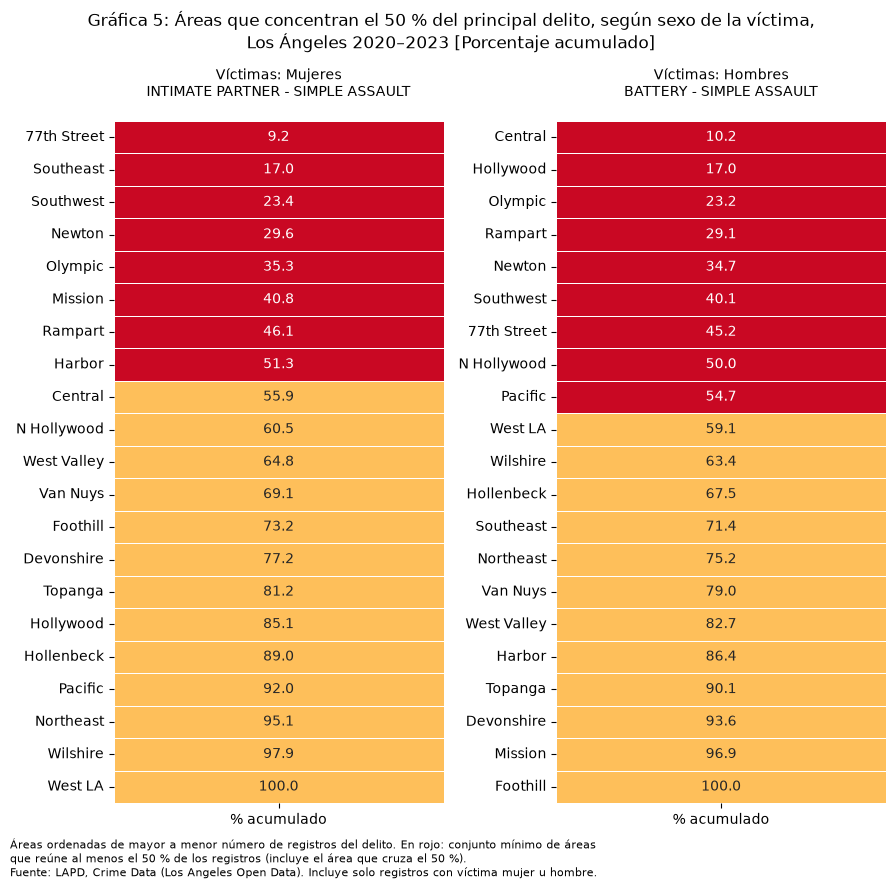

In [10]:
# Utilizamos los mismos colores de la pregunta 4
colores = sns.color_palette("YlOrRd", 5)
colores_grupo = [colores[1], colores[4]]

# Definimos el número de áreas en el grupo del 50 % para el principal delito
n_del_muj = areas_del_muj["grupo_50"].sum()
n_del_hom = areas_del_hom["grupo_50"].sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 8.5))

# Panel mujeres
sns.heatmap(areas_del_muj.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_del_muj[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[0])
axes[0].set_title(f"Víctimas: Mujeres\n{delito_muj}\n"
                  , fontsize=10)
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)

# Panel hombres
sns.heatmap(areas_del_hom.set_index("nom_area")[["grupo_50"]].astype(int),
            cmap=colores_grupo, vmin=0, vmax=1, cbar=False,
            annot=areas_del_hom[["pct_acum"]].to_numpy(), fmt=".1f",
            linewidths=0.5, linecolor="white",
            xticklabels=["% acumulado"], ax=axes[1])
axes[1].set_title(f"Víctimas: Hombres\n{delito_hom}\n"
                  , fontsize=10)
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Gráfica 5: Áreas que concentran el 50 % del principal delito, según sexo de la víctima,\n"
             "Los Ángeles 2020–2023 [Porcentaje acumulado]")
fig.text(0.01, -0.04,
         "Áreas ordenadas de mayor a menor número de registros del delito. En rojo: conjunto mínimo de áreas\n"
         "que reúne al menos el 50 % de los registros (incluye el área que cruza el 50 %).\n"
         "Fuente: LAPD, Crime Data (Los Angeles Open Data). Incluye solo registros con víctima mujer u hombre.",
         fontsize=8)
fig.tight_layout()
fig.savefig("../docs/imgs/figura_05.png", dpi=160, bbox_inches="tight")
plt.show()

#### Interpretación de la gráfica 5

- En la lesión simple por parte de la pareja íntima con víctima mujer, 8 de las 21 áreas reúnen al menos el 50 % de los registros, frente a 9 en el total de delitos contra mujeres (pregunta 4): está ligeramente más concentrada. Las tres primeras áreas (77th Street, Southeast y Southwest) se ubican en el sur de la ciudad y reúnen el 23.4 % de los registros. 
- En la lesión física simple con víctima hombre, 9 de 21 áreas reúnen el 50 %, igual que en el total de delitos contra hombres. Encabezan Central y Hollywood, áreas de alta actividad comercial y nocturna, lo que es coherente con los horarios de la pregunta 3.
- Ambos delitos comparten 5 áreas: 77th Street, Southwest, Newton, Olympic y Rampart.
- Solo dos áreas aparecen en los cuatro grupos (total de delitos y delito principal, para ambos sexos): 77th Street y Newton. A reserva de indagar más sobre el contexto y las rutinas de dichas áreas, este hallazgo puede servir para priorizar políticas de prevención del delito.

**Limitaciones:**
- Como en la pregunta 4, se usan cifras absolutas. El peso de Central puede reflejar su elevada población flotante y no un riesgo mayor para sus residentes.
- La violencia de pareja se denuncia menos que otros delitos, y la propensión a denunciar puede variar entre áreas; una concentración en los registros no equivale necesariamente a una concentración en la ocurrencia.

### Selección de hallazgos principales

Para el reporte seleccionamos tres hallazgos. La audiencia prevista es el público general y estudiantes interesados en la incidencia delictiva de Los Ángeles; elegimos los hallazgos que mejor responden a la pregunta central (cómo difieren los delitos según el sexo de la víctima) y que se sostienen al cambiar la forma de medir.

- **1. Los delitos que afectan a mujeres y hombres difieren en su composición y en su temporalidad.** Entre las mujeres, la lesión simple por parte de la pareja íntima forma parte de los tres delitos más frecuentes y se concentra en las noches de fin de semana; entre los hombres, el principal delito es la lesión física simple, concentrada en las tardes. *Por qué importa:* muestra que una política de prevención uniforme no atendería por igual a ambos grupos.

- **2. La concentración territorial es moderada, pero cambia al desagregar por tipo de delito y sexo.** Nueve de 21 áreas reúnen la mitad de los delitos de cada sexo; sin embargo, la violencia de pareja se concentra en el sur de la ciudad, mientras que la lesión simple contra hombres se concentra en áreas de alta actividad comercial y nocturna. *Por qué importa:* un análisis que solo considere el total de delitos ocultaría estas geografías específicas.

- **3. 77th Street y Newton aparecen de manera consistente.** Son las únicas áreas presentes en los cuatro grupos de concentración (total de delitos y delito principal, para ambos sexos). *Por qué importa:* es el hallazgo más robusto del análisis porque no depende del sexo de la víctima ni del tipo de delito; por ello es un punto de partida razonable para priorizar acciones, con la precaución de que se trata de cifras absolutas y no de tasas.